# Lab 13 — Validating a Clinical Prediction Model

**AI in Healthcare · Unit IV · B.Tech AI, Third Year · About 120 minutes**
**Lecture:** [Session 3 — Model validation, performance assessment, and challenges in healthcare data](../lectures/session-03-validation-performance.md)
**Previous lab:** [Lab 12 — Training an imaging model](lab-12-imaging-model-training.ipynb)
**Runs on:** any laptop CPU; no GPU or API needed.

## Objectives

In Session 3 you saw validation results. In this lab you produce them yourself and learn which choices make them honest or misleading:

1. **Split by the right unit.** Compare row-level and patient-level cross-validation on data where patients have many visits.
2. **Validate over time.** Train on earlier visits, test on later ones, and find out why the model's risks drifted.
3. **Validate externally.** Test a Cleveland heart-disease model at three other hospitals: discrimination, calibration, and threshold metrics with uncertainty.
4. **Recalibrate** the model for one hospital using part of its data, and check the result on the rest.
5. **Audit subgroups and errors**, and write a short validation report.

**Prerequisites:** Session 3 lecture notes; Lab 4 (logistic regression, sensitivity, specificity, PPV, NPV, AUROC). Basic pandas: filtering with masks, `groupby`. No medical knowledge is needed.

## Two datasets

| | Part 1–2: synthetic clinic visits | Parts 3–4: UCI Heart Disease |
|---|---|---|
| Source | **Hand-written generator in this notebook** (not Synthea, not real patients) | UCI Machine Learning Repository, four hospitals, CC BY 4.0 ([doi:10.24432/C52P4X](https://doi.org/10.24432/C52P4X)) |
| One row is | One clinic **visit**; each patient has 3–12 visits | One **patient** |
| Prediction target | Unplanned hospital admission within 90 days after the visit | Coronary heart disease on angiography (more than 50% narrowing of a major artery) |
| Why we use it | It has patient IDs and dates, so patient-level and temporal splits are possible | It has four real sites, so external validation is possible |

The synthetic data contain **deliberately planted features** that make validation mistakes visible. They are revealed during the lab. Synthetic results show how validation *methods* behave; they say nothing about real admission risk.

## Deliverables

Submit this notebook, run from top to bottom, with all `TODO` code completed, every ✍️ answer written, and the validation report in Part 5.

## Setup — 10 minutes

The cells below:

1. import the libraries (NumPy, pandas, scikit-learn, matplotlib — no installation needed in a standard Python data-science environment);
2. download the four UCI processed files (about 50 KB in total) on first run;
3. generate the synthetic visits table from a fixed seed.

**Files written** go to `lab13_data/` next to this notebook: the four UCI files (reused on reruns) and `synthetic_visits.csv` (**overwritten** on every run; it is regenerated identically). Do not commit them.

In [1]:
import urllib.request
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import GroupKFold, KFold, StratifiedKFold, cross_val_predict, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

SEED = 42
DATA_DIR = Path.cwd() / "lab13_data"
DATA_DIR.mkdir(exist_ok=True)
pd.set_option("display.width", 120)
print("scikit-learn", sklearn.__version__, "| data directory: ./lab13_data/")


def check(description, condition):
    print(("PASS  " if condition else "CHECK ") + description)

scikit-learn 1.8.0 | data directory: ./lab13_data/


In [2]:
# ---- UCI Heart Disease: four hospitals --------------------------------------------------
UCI_URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/"
SITE_FILES = {"Cleveland": "processed.cleveland.data", "Budapest": "processed.hungarian.data",
              "Zurich": "processed.switzerland.data", "Long Beach": "processed.va.data"}
UCI_COLUMNS = ["age", "sex", "cp", "trestbps", "chol", "fbs", "restecg", "thalach",
               "exang", "oldpeak", "slope", "ca", "thal", "num"]
EXPECTED_ROWS = {"Cleveland": 303, "Budapest": 294, "Zurich": 123, "Long Beach": 200}

SITES = {}
for site, fname in SITE_FILES.items():
    path = DATA_DIR / fname
    if not path.exists():
        urllib.request.urlretrieve(UCI_URL + fname, path)
    df = pd.read_csv(path, header=None, names=UCI_COLUMNS, na_values="?")
    df["target"] = (df["num"] > 0).astype(int)        # 0 = no disease, 1-4 = disease present
    SITES[site] = df
    check(f"{site}: {len(df)} patients (expected {EXPECTED_ROWS[site]})", len(df) == EXPECTED_ROWS[site])

PASS  Cleveland: 303 patients (expected 303)
PASS  Budapest: 294 patients (expected 294)
PASS  Zurich: 123 patients (expected 123)
PASS  Long Beach: 200 patients (expected 200)


In [3]:
# ---- Synthetic clinic visits (hand-written generator; fictional patients) ---------------
def make_visits(seed=13, n_patients=500):
    """Each patient enrols on a random date and has 3-12 visits within the next two years.
    The 90-day admission label is drawn from a logistic model of the TRUE values, plus a
    patient-level 'frailty' that is never recorded. Visits end on 2024-09-30 so every visit
    has 90 days of follow-up. Planted features are documented in Part 2."""
    rng = np.random.default_rng(seed)
    start, last_visit = pd.Timestamp("2021-01-01"), pd.Timestamp("2024-09-30")
    span = (last_visit - start).days
    rows = []
    for pid in range(1, n_patients + 1):
        frailty = rng.normal()                       # unrecorded patient-level risk
        height = rng.normal(165, 9)
        weight0 = rng.normal(72, 13)
        age0 = rng.integers(40, 86)
        sbp0 = rng.normal(132, 15) + 4 * frailty
        hba1c0 = rng.normal(6.4, 1.0) + 0.3 * frailty
        enrol = int(rng.integers(0, span - 180))
        window = min(730, span - enrol)
        days = enrol + np.sort(rng.choice(window, rng.integers(3, 13), replace=False))
        for d in days:
            date = start + pd.Timedelta(days=int(d))
            new_device = date >= pd.Timestamp("2023-07-01")
            sbp_true = sbp0 + rng.normal(0, 8)
            sbp_recorded = sbp_true + (12 if new_device else 0)
            hba1c = hba1c0 + rng.normal(0, 0.3)
            age = age0 + d / 365.25
            log_odds = (-2.3 + 0.04 * (age - 65) + 0.025 * (sbp_true - 130)
                        + 0.45 * (hba1c - 6.4) + 2.0 * frailty)
            rows.append({"patient_id": f"P{pid:04d}", "visit_date": date.date().isoformat(),
                         "age": round(age, 1), "height_cm": round(height, 1),
                         "weight_kg": round(weight0 + rng.normal(0, 1.5), 1),
                         "systolic_bp": round(sbp_recorded), "hba1c_pct": round(hba1c, 1),
                         "admitted_90d": int(rng.random() < 1 / (1 + np.exp(-log_odds)))})
    return pd.DataFrame(rows)


visits = make_visits()
visits.to_csv(DATA_DIR / "synthetic_visits.csv", index=False)
visits["visit_date"] = pd.to_datetime(visits["visit_date"])
FEATURES = ["age", "height_cm", "weight_kg", "systolic_bp", "hba1c_pct"]
visits.head()

,patient_id,visit_date,age,height_cm,weight_kg,systolic_bp,hba1c_pct,admitted_90d
0,P0001,2021-11-08,83.9,137.3,81.7,155,7.2,1
1,P0001,2022-02-11,84.1,137.3,85.1,157,7.7,1
2,P0001,2022-06-03,84.4,137.3,86.7,171,7.4,1
3,P0001,2023-01-24,85.1,137.3,85.0,169,6.9,1
4,P0001,2023-05-31,85.4,137.3,83.2,161,7.2,1


**Columns.** `systolic_bp` is the upper blood-pressure reading (mm Hg). `hba1c_pct` is **HbA1c**, a blood test reflecting average blood sugar over about three months (%). `admitted_90d` is 1 if the patient had an unplanned hospital admission in the 90 days after the visit.

## Part 1 — Rows, patients, and the splitting unit (25 minutes)

### Exercise 1.1 — What is a row?

Complete the cell: count the rows, the distinct patients, and the visits per patient (minimum, median, maximum). Hint: `visits.groupby("patient_id").size()` returns one number per patient — the number of rows (visits) that patient has.

In [4]:
n_rows = len(visits)
n_patients = visits["patient_id"].nunique()
visits_per_patient = visits.groupby("patient_id").size()        # a Series: one value per patient
admission_rate = visits["admitted_90d"].mean()            # proportion of VISITS with admitted_90d == 1

print("rows (visits):", n_rows, "| patients:", n_patients)
if visits_per_patient is not None:
    print("visits per patient: min", visits_per_patient.min(), "median", visits_per_patient.median(),
          "max", visits_per_patient.max())
print("admission rate per visit:", admission_rate)
check("500 patients", n_patients == 500)
check("more rows than patients", n_rows is not None and n_rows > 500)

rows (visits): 3748 | patients: 500
visits per patient: min 3 median 8.0 max 12
admission rate per visit: 0.24733191035218782
PASS  500 patients
PASS  more rows than patients


In [5]:
per_patient = visits.groupby("patient_id")[["height_cm", "systolic_bp", "hba1c_pct"]].std().mean()
print("Average within-patient standard deviation across visits:")
print(per_patient.round(2))

Average within-patient standard deviation across visits:
height_cm      0.00
systolic_bp    8.47
hba1c_pct      0.28
dtype: float64


Notice that `height_cm` is identical at every visit of a patient. A flexible model can use it as a **fingerprint**: if a patient's earlier visits are in the training data, the model can recognise the patient and recall how often they were admitted.

### Exercise 1.2 — Row-level versus patient-level cross-validation

`cv_auroc` runs 5-fold cross-validation and returns the AUROC of the out-of-fold predictions (every visit is scored by a model that did not train on that visit).

- **Row-level:** `KFold` assigns *visits* to folds at random, so one patient's visits can be split across training and test folds.
- **Patient-level:** `GroupKFold` keeps all visits of a patient in the same fold.

Complete the patient-level call for both models.

In [6]:
def make_logreg():
    return make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))


def make_forest():
    # min_samples_leaf=1 lets trees fit individual visits, which makes memorisation possible
    return RandomForestClassifier(n_estimators=300, min_samples_leaf=1, random_state=0, n_jobs=-1)


def cv_auroc(model, cv, groups=None):
    p = cross_val_predict(model, visits[FEATURES], visits["admitted_90d"], cv=cv, groups=groups,
                          method="predict_proba")[:, 1]
    return round(roc_auc_score(visits["admitted_90d"], p), 3)


row_cv = KFold(n_splits=5, shuffle=True, random_state=0)
patient_cv = GroupKFold(n_splits=5)

results_split = []
for name, make in [("logistic regression", make_logreg), ("random forest", make_forest)]:
    row = cv_auroc(make(), row_cv)
    patient = cv_auroc(make(), patient_cv, groups=visits["patient_id"])
    results_split.append({"model": name, "row-level CV AUROC": row, "patient-level CV AUROC": patient})

split_table = pd.DataFrame(results_split)
split_table

,model,row-level CV AUROC,patient-level CV AUROC
0,logistic regression,0.733,0.721
1,random forest,0.803,0.669


### Exercise 1.3 — Interpret

✍️ **Your answer** (4–6 sentences):

1. For which model does the splitting unit change the result, and by how much?
2. Explain *why* the random forest benefits from a row-level split but logistic regression hardly does. (Think about the fingerprint, and about what each model can represent.)
3. Which number would you report as the internal validation result, and why?
4. Under row-level CV, the random forest looks better than logistic regression. Under patient-level CV, which is better? What would have happened if you had chosen the model using row-level CV?

**Answer**

The random forest’s AUROC fell by 0.134, from 0.803 with row-level CV to 0.669 with patient-level CV, while logistic regression fell by 0.012, from 0.733 to 0.721. With a row-level split, the forest can use fixed height together with other stable features to recognise patients and learn patterns linked to their unrecorded frailty from visits in the training folds. Logistic regression fits additive effects on the log-odds scale, which gives it much less capacity to recognise individual patient fingerprints. I would report the patient-level AUROCs for internal validation because each test fold contains patients absent from its training fold. Row-level CV would have selected the forest, while patient-level CV favours logistic regression by 0.052 AUROC on unseen patients.

## Part 2 — Temporal validation and drift (20 minutes)

A model is used on **future** patients. A temporal validation imitates this: train on earlier data, test on later data.

- **Training period:** visits before 1 January 2023.
- **Test period:** visits from 1 January 2024 to 30 September 2024.
- The year 2023 is left out, a gap like the time between building a model and deploying it.

Logistic regression is used here, because Part 1 showed it is the more trustworthy choice.

In [7]:
train_mask = visits["visit_date"] < "2023-01-01"
test_mask = visits["visit_date"] >= "2024-01-01"
train, test = visits[train_mask], visits[test_mask]
seen_patients = set(train["patient_id"])
print(f"train: {len(train)} visits, {train['patient_id'].nunique()} patients | "
      f"test: {len(test)} visits, {test['patient_id'].nunique()} patients "
      f"({test['patient_id'].isin(seen_patients).mean():.0%} of test visits from patients also in training)")

temporal_model = make_logreg().fit(train[FEATURES], train["admitted_90d"])
p_temporal = temporal_model.predict_proba(test[FEATURES])[:, 1]
print("temporal test AUROC:", round(roc_auc_score(test["admitted_90d"], p_temporal), 3))

train: 1151 visits, 261 patients | test: 1307 visits, 309 patients (15% of test visits from patients also in training)
temporal test AUROC: 0.724


### Exercise 2.1 — Calibration over time

Complete `calibration_in_the_large(y, p)`: return a dictionary with `mean_predicted`, `observed_rate`, and their ratio `observed_to_expected` (observed ÷ mean predicted). Then look at the reliability diagram: `plot_reliability` groups predictions into ten equal-sized bins and plots each bin's observed rate against its mean prediction.

training period: {'mean_predicted': np.float64(0.24674657060572672), 'observed_rate': np.float64(0.2467419635099913), 'observed_to_expected': np.float64(0.9999813286331636)}
test period:     {'mean_predicted': np.float64(0.3283574403102276), 'observed_rate': np.float64(0.23106350420811017), 'observed_to_expected': np.float64(0.7036950464402589)}


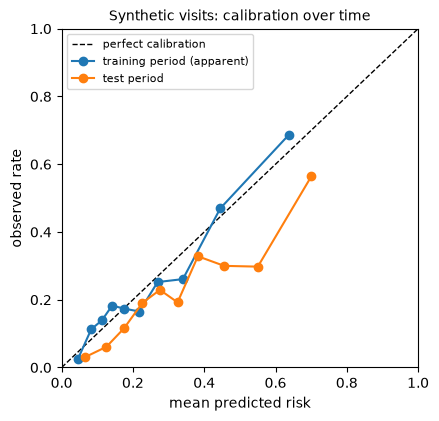

In [8]:
def calibration_in_the_large(y, p):
    y, p = np.asarray(y), np.asarray(p)
    mean_predicted, observed_rate = p.mean(), y.mean()
    return {"mean_predicted": mean_predicted, "observed_rate": observed_rate,
            "observed_to_expected": observed_rate / mean_predicted if mean_predicted else np.nan}


def plot_reliability(curves, title, n_bins=10):
    """curves: dict label -> (y, p). Equal-count bins of predicted risk."""
    fig, ax = plt.subplots(figsize=(4.6, 4.4))
    ax.plot([0, 1], [0, 1], "k--", lw=1, label="perfect calibration")
    for label, (y, p) in curves.items():
        frame = pd.DataFrame({"y": np.asarray(y), "p": np.asarray(p)})
        frame["bin"] = pd.qcut(frame["p"], q=min(n_bins, len(frame) // 10 or 1), duplicates="drop")
        g = frame.groupby("bin", observed=True).agg(p=("p", "mean"), y=("y", "mean"))
        ax.plot(g["p"], g["y"], "o-", label=label)
    ax.set_xlabel("mean predicted risk"); ax.set_ylabel("observed rate")
    ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.legend(fontsize=8); ax.set_title(title, fontsize=10)
    plt.show()


p_train_fit = temporal_model.predict_proba(train[FEATURES])[:, 1]
print("training period:", calibration_in_the_large(train["admitted_90d"], p_train_fit))
print("test period:    ", calibration_in_the_large(test["admitted_90d"], p_temporal))
plot_reliability({"training period (apparent)": (train["admitted_90d"], p_train_fit),
                  "test period": (test["admitted_90d"], p_temporal)}, "Synthetic visits: calibration over time")

### Exercise 2.2 — Find the cause

The model now **overpredicts**. Something about the data changed. Plot the **monthly mean** of each input over the whole period and look for a change. Hint: `visits.set_index("visit_date")[col].resample("MS").mean()` gives one mean per month (`"MS"` = month start).

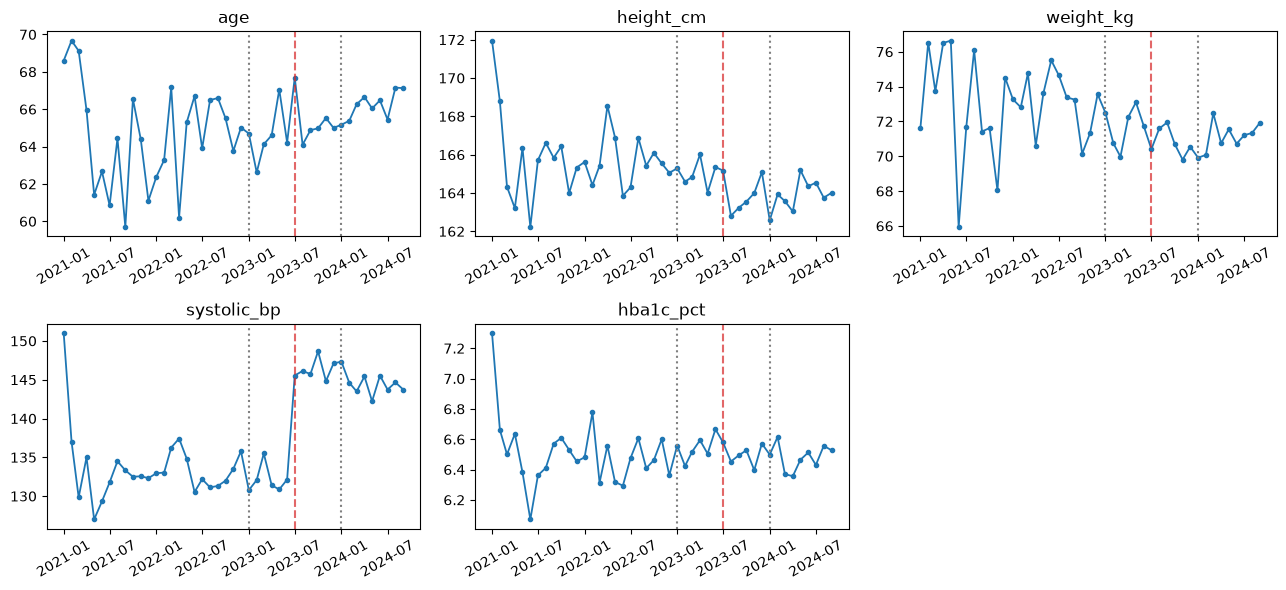

June and July 2023 monthly means:


,age,height_cm,weight_kg,systolic_bp,hba1c_pct
visit_date,,,,,
2023-06-01,64.21,165.36,71.73,132.14,6.67
2023-07-01,67.69,165.17,70.41,145.54,6.58


Test after correcting device offset: {'mean_predicted': np.float64(0.2526626894097114), 'observed_rate': np.float64(0.23106350420811017), 'observed_to_expected': np.float64(0.9145137524972017)}
Corrected test AUROC: 0.724


In [9]:
monthly_inputs = visits.set_index("visit_date")[FEATURES].resample("MS").mean()
fig, axes = plt.subplots(2, 3, figsize=(13, 6))
axes.flat[-1].axis("off")
for ax, col in zip(axes.flat, FEATURES):
    ax.plot(monthly_inputs.index, monthly_inputs[col], marker=".", linewidth=1.3)
    ax.axvline(pd.Timestamp("2023-07-01"), color="tab:red", ls="--", alpha=0.7)
    ax.set_title(col)
    ax.tick_params(axis="x", labelrotation=30)
    ax.axvline(pd.Timestamp("2023-01-01"), color="grey", ls=":")
    ax.axvline(pd.Timestamp("2024-01-01"), color="grey", ls=":")
plt.tight_layout()
plt.show()

print("June and July 2023 monthly means:")
display(monthly_inputs.loc["2023-06":"2023-07"].round(2))

# Compare on the same test visits after undoing the known measurement shift.
test_corrected = test[FEATURES].assign(systolic_bp=test["systolic_bp"] - 12)
p_corrected = temporal_model.predict_proba(test_corrected)[:, 1]
print("Test after correcting device offset:", calibration_in_the_large(test["admitted_90d"], p_corrected))
print("Corrected test AUROC:", round(roc_auc_score(test["admitted_90d"], p_corrected), 3))

### Exercise 2.3 — Interpret

✍️ **Your answer** (4–6 sentences):

1. Which input changed, when, and by roughly how much?
2. Why did that change make the model overpredict, even though the patients' true risk did not change?
3. Did AUROC reveal the problem? Why or why not?
4. Name two things a hospital could do to detect such a change after deployment, and one way to correct the model.

**Answer**

Recorded systolic blood pressure rose abruptly at the July 2023 device change, from a monthly mean of 132.14 mm Hg in June to 145.54 mm Hg in July, with a planted offset of 12 mm Hg per visit. The model assigns more risk to higher systolic pressure, so the offset inflated predictions even though the generator uses true pressure to determine admission risk. In the test period, mean predicted risk was 32.84% versus 23.11% observed (O/E 0.70), and subtracting the offset lowered mean predicted risk to 25.27%. AUROC was 0.724 both before and after correction because the fixed offset shifted all test log-odds by the same amount and preserved their ranking. A hospital could track input distributions by device and compare predicted risks with observed outcomes once follow-up is complete. It could then harmonise the new device’s readings to the training scale after confirming the offset with paired measurements.

**Planted features of the synthetic data (revealed after Exercise 2.3).**

| Planted feature | Detail | What it demonstrates |
|---|---|---|
| Repeated visits and a fixed `height_cm` | 3–12 visits per patient; height identical at every visit | Patient overlap rewards memorisation under row-level splits |
| Unrecorded frailty | A patient-level risk factor that drives admissions but is not in the data | Why memorising a patient helps a row-level score |
| Blood-pressure device change | From 1 July 2023, `systolic_bp` is recorded **12 mm Hg higher** than the true value; the label depends on the true value | Measurement drift causes miscalibration without changing true risk |

## Part 3 — External validation on four real hospitals (25 minutes)

Now the real UCI data. As in Session 3, the model is a logistic regression on eight inputs recorded at all four sites. At each external site, patients missing any of these inputs are excluded, and the number excluded is reported.

`validation_report` computes, for one site: AUROC with a bootstrap 95% CI, calibration-in-the-large (your function from Part 2), the calibration slope, and sensitivity, specificity, PPV and NPV at a threshold of 0.5 with Wilson 95% CIs.

In [10]:
CORE = ["age", "sex", "cp", "trestbps", "thalach", "exang", "oldpeak", "restecg"]


def design(df):
    """Core inputs, with chest-pain type and resting ECG one-hot encoded (reference levels dropped)."""
    x = df[CORE].copy()
    x[["cp", "restecg"]] = x[["cp", "restecg"]].astype(int)
    x = pd.get_dummies(x, columns=["cp", "restecg"], dtype=float)
    for col in ["cp_1", "cp_2", "cp_3", "cp_4", "restecg_0", "restecg_1", "restecg_2"]:
        if col not in x:
            x[col] = 0.0
    return x[sorted(x.columns)].drop(columns=["cp_1", "restecg_0"])


def wilson(k, n, z=1.96):
    if n == 0:
        return (np.nan, np.nan)
    p = k / n
    centre = (p + z * z / (2 * n)) / (1 + z * z / n)
    half = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / (1 + z * z / n)
    return (centre - half, centre + half)


def boot_auroc_ci(y, p, n_boot=1000):
    rng = np.random.default_rng(SEED)
    vals = [roc_auc_score(y[i], p[i]) for i in (rng.integers(0, len(y), len(y)) for _ in range(n_boot))
            if 0 < y[i].sum() < len(i)]
    return np.percentile(vals, [2.5, 97.5])


def calibration_slope(y, p):
    p = np.clip(np.asarray(p), 1e-6, 1 - 1e-6)
    logit = np.log(p / (1 - p)).reshape(-1, 1)
    return LogisticRegression(C=np.inf, max_iter=1000).fit(logit, y).coef_[0, 0]


def fmt(k, n):
    if n == 0:
        return "undefined"
    lo, hi = wilson(k, n)
    return f"{k}/{n} = {k / n:.2f} ({lo:.2f}-{hi:.2f})"


def validation_report(label, y, p, threshold=0.5):
    y, p = np.asarray(y), np.asarray(p)
    yhat = p >= threshold
    tp, fn = int((yhat & (y == 1)).sum()), int((~yhat & (y == 1)).sum())
    tn, fp = int((~yhat & (y == 0)).sum()), int((yhat & (y == 0)).sum())
    lo, hi = boot_auroc_ci(y, p)
    cal = calibration_in_the_large(y, p)
    return {"site": label, "n": len(y), "with disease": f"{int(y.sum())} ({y.mean():.0%})",
            "AUROC (95% CI)": f"{roc_auc_score(y, p):.2f} ({lo:.2f}-{hi:.2f})",
            "mean predicted": cal["mean_predicted"], "observed rate": cal["observed_rate"],
            "observed / expected": cal["observed_to_expected"], "calibration slope": round(calibration_slope(y, p), 2),
            "sensitivity": fmt(tp, tp + fn), "specificity": fmt(tn, tn + fp),
            "PPV": fmt(tp, tp + fp), "NPV": fmt(tn, tn + fn)}


dev = SITES["Cleveland"]
heart_model = make_logreg().fit(design(dev), dev["target"])
p_internal = cross_val_predict(make_logreg(), design(dev), dev["target"],
                               cv=StratifiedKFold(10, shuffle=True, random_state=SEED), method="predict_proba")[:, 1]

EXTERNAL = {}
reports = [validation_report("Cleveland (internal, 10-fold CV)", dev["target"], p_internal)]
for site in ["Budapest", "Zurich", "Long Beach"]:
    df = SITES[site]
    keep = df[CORE].notna().all(axis=1)
    print(f"{site}: excluded {int((~keep).sum())} of {len(df)} for missing core inputs")
    EXTERNAL[site] = df[keep].reset_index(drop=True)
    p = heart_model.predict_proba(design(EXTERNAL[site]))[:, 1]
    EXTERNAL[site]["p"] = p
    reports.append(validation_report(site, EXTERNAL[site]["target"], p))

external_table = pd.DataFrame(reports).set_index("site")
external_table.T

C:\Users\anshu\AppData\Local\Temp\lab13-617f2318-e82f-4d50-84ed-178164761760\packages\sklearn\linear_model\_logistic.py:1170: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
  warnings.warn(


Budapest: excluded 2 of 294 for missing core inputs


C:\Users\anshu\AppData\Local\Temp\lab13-617f2318-e82f-4d50-84ed-178164761760\packages\sklearn\linear_model\_logistic.py:1170: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
  warnings.warn(


Zurich: excluded 7 of 123 for missing core inputs


C:\Users\anshu\AppData\Local\Temp\lab13-617f2318-e82f-4d50-84ed-178164761760\packages\sklearn\linear_model\_logistic.py:1170: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
  warnings.warn(


Long Beach: excluded 59 of 200 for missing core inputs


C:\Users\anshu\AppData\Local\Temp\lab13-617f2318-e82f-4d50-84ed-178164761760\packages\sklearn\linear_model\_logistic.py:1170: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
  warnings.warn(


site,"Cleveland (internal, 10-fold CV)",Budapest,Zurich,Long Beach
n,303,292,116,141
with disease,139 (46%),105 (36%),108 (93%),111 (79%)
AUROC (95% CI),0.87 (0.84-0.91),0.88 (0.83-0.92),0.75 (0.59-0.91),0.72 (0.61-0.82)
mean predicted,0.458864,0.410187,0.683543,0.796289
observed rate,0.458746,0.359589,0.931034,0.787234
observed / expected,0.999743,0.876647,1.362071,0.988628
calibration slope,0.88,0.89,0.54,0.48
sensitivity,104/139 = 0.75 (0.67-0.81),81/105 = 0.77 (0.68-0.84),83/108 = 0.77 (0.68-0.84),104/111 = 0.94 (0.88-0.97)
specificity,140/164 = 0.85 (0.79-0.90),156/187 = 0.83 (0.77-0.88),4/8 = 0.50 (0.22-0.78),8/30 = 0.27 (0.14-0.44)
PPV,104/128 = 0.81 (0.74-0.87),81/112 = 0.72 (0.63-0.80),83/87 = 0.95 (0.89-0.98),104/126 = 0.83 (0.75-0.88)


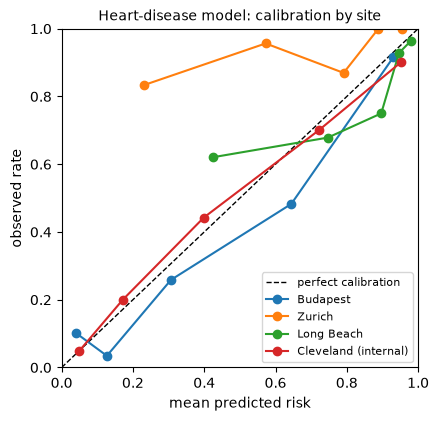

In [11]:
plot_reliability({site: (EXTERNAL[site]["target"], EXTERNAL[site]["p"]) for site in EXTERNAL}
                 | {"Cleveland (internal)": (dev["target"], p_internal)},
                 "Heart-disease model: calibration by site", n_bins=5)

### Exercise 3.1 — Interpret the external validation

✍️ **Your answer** (6–8 sentences):

1. At which site does the model **rank** patients about as well as in Cleveland? Where is it clearly worse? Use the confidence intervals.
2. Describe the **calibration** at each external site in words (over- or underprediction; too extreme or not).
3. Long Beach's mean predicted risk is close to its observed rate, yet its calibration slope is about 0.5. What does that mean for individual patients?
4. Zurich's specificity is reported as a fraction. How many patients is it based on, and what can you conclude from it?
5. Long Beach excluded many patients. How could this exclusion bias the results?

**Answer**

Budapest ranked patients about as well as Cleveland, with AUROC 0.88 (95% CI 0.83–0.92) versus 0.87 (0.84–0.91). Long Beach showed clearly poorer ranking in this comparison, with AUROC 0.72 (0.61–0.82) and an interval below Cleveland’s, while Zurich’s lower estimate of 0.75 had a wide interval (0.59–0.91) that overlapped Cleveland’s. Budapest mildly overpredicted on average (41.0% predicted versus 36.0% observed), with a slope of 0.89 suggesting slightly over-extreme predictions. Zurich substantially underpredicted on average (68.4% versus 93.1%) and its slope of 0.54 also suggests overly extreme predictions on the log-odds scale. Long Beach slightly overpredicted on average (79.6% versus 78.7%), but its slope of 0.48 means the spread of individual log-odds should be compressed around the local risk level, bringing very low and very high estimates closer to the middle. Zurich’s specificity was based on just eight patients without disease (4/8, 95% Wilson CI 0.22–0.78), so its true specificity remains poorly estimated. Long Beach excluded 59 of 200 patients, and its estimates could be biased in either direction if missingness was related to disease severity, test ordering, or how hard patients were to classify.

### Exercise 3.2 — Recalibrate the model for Budapest

Budapest's discrimination is good but its risks are slightly too high. **Logistic recalibration** keeps the model and fits two numbers on local data: a new intercept $a$ and slope $b$ applied to the model's log-odds:

$$\text{recalibrated log-odds} = a + b \times \text{original log-odds}$$

To avoid evaluating on the data used for fitting, split Budapest in half (stratified by outcome). Complete `fit_recalibration` so it fits a logistic regression (no penalty) of the outcome on the original log-odds of the **fitting half** and returns a function that maps new probabilities to recalibrated ones.

In [12]:
def logit(p):
    p = np.clip(np.asarray(p), 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p)).reshape(-1, 1)


def fit_recalibration(y_fit, p_fit):
    calibrator = LogisticRegression(C=np.inf, max_iter=1000).fit(logit(p_fit), y_fit)
    return lambda p_new: calibrator.predict_proba(logit(p_new))[:, 1]


bud = EXTERNAL["Budapest"]
fit_half, eval_half = train_test_split(bud, test_size=0.5, stratify=bud["target"], random_state=SEED)
recalibrate = fit_recalibration(fit_half["target"], fit_half["p"])
p_before, p_after = eval_half["p"].to_numpy(), recalibrate(eval_half["p"])

y_eval = eval_half["target"].to_numpy()
print(f"Budapest recalibration: {len(fit_half)} fitting patients, {len(eval_half)} evaluation patients")
print("evaluation half, before:", calibration_in_the_large(y_eval, p_before),
      "| slope", round(calibration_slope(y_eval, p_before), 2), "| AUROC", round(roc_auc_score(y_eval, p_before), 3))
print("evaluation half, after: ", calibration_in_the_large(y_eval, p_after),
      "| slope", round(calibration_slope(y_eval, np.clip(p_after, 1e-6, 1 - 1e-6)), 2),
      "| AUROC", round(roc_auc_score(y_eval, p_after), 3))
check("recalibration changed the predictions", not np.allclose(p_before, p_after))

Budapest recalibration: 146 fitting patients, 146 evaluation patients
evaluation half, before: {'mean_predicted': np.float64(0.3938031790715844), 'observed_rate': np.float64(0.3561643835616438), 'observed_to_expected': np.float64(0.9044223167556026)} | slope 0.96 | AUROC 0.893
evaluation half, after:  {'mean_predicted': np.float64(0.33514919662173087), 'observed_rate': np.float64(0.3561643835616438), 'observed_to_expected': np.float64(1.062703975279499)} | slope 1.16 | AUROC 0.893
PASS  recalibration changed the predictions


C:\Users\anshu\AppData\Local\Temp\lab13-617f2318-e82f-4d50-84ed-178164761760\packages\sklearn\linear_model\_logistic.py:1170: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
  warnings.warn(
C:\Users\anshu\AppData\Local\Temp\lab13-617f2318-e82f-4d50-84ed-178164761760\packages\sklearn\linear_model\_logistic.py:1170: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
  warnings.warn(
C:\Users\anshu\AppData\Local\Temp\lab13-617f2318-e82f-4d50-84ed-178164761760\packages\sklearn\linear_model\_logistic.py:1170: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
  warnings.warn(


✍️ **Your answer** (3–4 sentences): What changed in calibration on the evaluation half? Why did AUROC stay the same? With 146 patients in the fitting half, what is the risk of recalibrating on so little data, and what would you require before using the recalibrated model?

**Answer**

On the 146-patient evaluation half, mean predicted risk fell from 39.38% to 33.51% against an observed rate of 35.62%, so the absolute calibration gap narrowed and the direction shifted from overprediction to underprediction. The slope moved from 0.96 to 1.16, farther from 1, so recalibration improved the average risk estimate while worsening the slope estimate. AUROC stayed at 0.893 because the positive recalibration slope preserved the ordering of patients. With only 146 fitting patients, the intercept and slope can be sensitive to sampling variation, so I would require a larger independent local cohort to confirm calibration and threshold performance before use.

## Part 4 — Subgroup audit and error analysis (25 minutes)

### Exercise 4.1 — Performance by sex

Complete `subgroup_table(df, y_col, p_col, group_col)`: for each value of `group_col`, return the number of patients, the number with disease, AUROC, and sensitivity and specificity at 0.5 formatted with `fmt` (which includes Wilson CIs). Then apply it to Cleveland's internal (cross-validated) predictions and to Budapest.

In [13]:
def subgroup_table(df, y_col, p_col, group_col, threshold=0.5):
    rows = []
    for value, g in df.groupby(group_col):
        y, p = g[y_col].to_numpy(), g[p_col].to_numpy()
        yhat = p >= threshold
        diseased = y == 1
        tp, fn = int((yhat & diseased).sum()), int((~yhat & diseased).sum())
        tn, fp = int((~yhat & ~diseased).sum()), int((yhat & ~diseased).sum())
        rows.append({"group": value, "n": len(g), "with disease": tp + fn,
                     "AUROC": round(roc_auc_score(y, p), 3) if np.unique(y).size == 2 else np.nan,
                     "sensitivity": fmt(tp, tp + fn), "specificity": fmt(tn, tn + fp)})
    return pd.DataFrame(rows)


SEX = {0: "women", 1: "men"}
cle = dev.assign(p=p_internal, group=dev["sex"].map(SEX))
display(subgroup_table(cle, "target", "p", "group").assign(site="Cleveland (internal)"))
display(subgroup_table(EXTERNAL["Budapest"].assign(group=EXTERNAL["Budapest"]["sex"].map(SEX)),
                       "target", "p", "group").assign(site="Budapest"))

,group,n,with disease,AUROC,sensitivity,specificity,site
0,men,206,114,0.842,86/114 = 0.75 (0.67-0.82),72/92 = 0.78 (0.69-0.85),Cleveland (internal)
1,women,97,25,0.894,18/25 = 0.72 (0.52-0.86),68/72 = 0.94 (0.87-0.98),Cleveland (internal)


,group,n,with disease,AUROC,sensitivity,specificity,site
0,men,212,93,0.877,75/93 = 0.81 (0.71-0.87),93/119 = 0.78 (0.70-0.85),Budapest
1,women,80,12,0.784,6/12 = 0.50 (0.25-0.75),63/68 = 0.93 (0.84-0.97),Budapest


✍️ **Your answer** (4–5 sentences): Is there evidence that the model detects disease less well in women? How many women with disease does each estimate rest on? Which fairness criterion (equal sensitivity, equal specificity, or equal PPV) matters most for a referral tool, and can you check it reliably with these data?

**Answer**

At 0.5, women had lower estimated sensitivity than men in Cleveland (72% versus 75%) and especially in Budapest (50% versus 81%). Those estimates rest on 25 women with disease in Cleveland and 12 in Budapest, with Wilson intervals of 52–86% and 25–75%, respectively. The Budapest gap is concerning, but the small denominators and wide intervals leave substantial uncertainty about its size and reproducibility. Equal sensitivity matters most for a referral tool because patients with disease should have a comparable chance of being flagged across groups. These data are too sparse to assess sensitivity parity reliably, so the gap should be evaluated in a larger cohort with more disease-positive women.

### Exercise 4.2 — Look at the errors

Use Budapest at a threshold of 0.5. List the false negatives (disease, predicted below 0.5) and false positives, then compare the distribution of chest-pain type (`cp`) among errors with all Budapest patients. `cp` codes: 1 typical angina, 2 atypical angina, 3 non-anginal pain, 4 asymptomatic.

In [14]:
bud = EXTERNAL["Budapest"].copy()
bud["error"] = np.select([(bud["target"] == 1) & (bud["p"] < 0.5), (bud["target"] == 0) & (bud["p"] >= 0.5)],
                         ["false negative", "false positive"], default="correct")
print(bud["error"].value_counts())

#           Hint: pd.crosstab(bud["error"], bud["cp"], normalize="index")
cp_labels = {1: "Typical angina", 2: "Atypical angina", 3: "Non-anginal pain", 4: "Asymptomatic"}
cp_by_error = pd.crosstab(bud["error"], bud["cp"], normalize="index")
cp_by_error.loc["all Budapest"] = bud["cp"].value_counts(normalize=True)
cp_by_error = cp_by_error.reindex(columns=cp_labels, fill_value=0).rename(columns=cp_labels)
cp_by_error.round(3)

error
correct           237
false positive     31
false negative     24
Name: count, dtype: int64


cp,Typical angina,Atypical angina,Non-anginal pain,Asymptomatic
error,,,,
correct,0.030,0.418,0.173,0.380
false negative,0.125,0.125,0.417,0.333
false positive,0.000,0.097,0.097,0.806
all Budapest,0.034,0.360,0.185,0.421


In [15]:
cols = CORE + ["target", "p"]
for error, ascending in [("false negative", True), ("false positive", False)]:
    cases = bud.loc[bud["error"] == error, cols].sort_values("p", ascending=ascending)
    print(f"{error.title()}s ({len(cases)} patients):")
    display(cases.round(3))

chest_pain_coefficients = pd.Series(
    heart_model.named_steps["logisticregression"].coef_[0] /
    heart_model.named_steps["standardscaler"].scale_,
    index=design(dev).columns,
).filter(like="cp_")
print("Adjusted chest-pain odds ratios relative to typical angina:")
display(np.exp(chest_pain_coefficients).round(2))

False Negatives (24 patients):


,age,sex,cp,trestbps,thalach,exang,oldpeak,restecg,target,p
255,47,0,3,135.0,170.0,0.0,0.0,0.0,1,0.017
189,34,1,1,140.0,180.0,0.0,0.0,0.0,1,0.046
209,49,1,3,115.0,175.0,0.0,0.0,0.0,1,0.058
208,49,0,3,160.0,156.0,0.0,1.0,0.0,1,0.065
269,56,0,2,120.0,150.0,0.0,1.0,0.0,1,0.072
211,50,0,3,140.0,140.0,1.0,0.0,0.0,1,0.079
228,43,1,1,120.0,155.0,0.0,0.0,1.0,1,0.101
190,35,1,2,110.0,140.0,0.0,0.0,0.0,1,0.120
254,46,1,1,140.0,175.0,0.0,2.0,0.0,1,0.209
288,54,0,3,130.0,100.0,1.0,0.0,1.0,1,0.222


False Positives (31 patients):


,age,sex,cp,trestbps,thalach,exang,oldpeak,restecg,target,p
136,53,1,4,124.0,112.0,1.0,3.0,1.0,0,0.980
164,55,1,4,140.0,110.0,1.0,0.5,0.0,0,0.906
184,61,1,4,125.0,115.0,1.0,0.0,1.0,0,0.895
154,54,1,4,150.0,134.0,0.0,1.0,1.0,0,0.860
84,46,1,4,180.0,120.0,0.0,0.0,1.0,0,0.856
82,46,1,4,110.0,140.0,1.0,1.0,1.0,0,0.833
171,57,0,4,180.0,126.0,1.0,0.8,1.0,0,0.827
89,47,1,4,140.0,125.0,1.0,0.0,0.0,0,0.805
176,58,1,4,135.0,100.0,0.0,0.0,0.0,0,0.794
114,50,1,4,150.0,140.0,1.0,0.0,0.0,0,0.793


Adjusted chest-pain odds ratios relative to typical angina:


cp_2    1.91
cp_3    1.19
cp_4    8.29
dtype: float64

✍️ **Your answer** (4–6 sentences): Is there a pattern in the false negatives (for example, a chest-pain type, sex, or exercise results)? Link it to what Session 5 found about the chest-pain coefficient. Would you change the model's intended use because of this pattern, or collect more data first?

**Answer**

Non-anginal pain accounted for 10 of 24 false negatives (41.7%) versus 18.5% of all Budapest patients, while 25 of 31 false positives (80.6%) were asymptomatic versus 42.1% overall. The fitted chest-pain coefficient illustrates the pattern relevant to Session 5: relative to typical angina, asymptomatic status multiplied the model’s adjusted odds by 8.29, compared with 1.19 for non-anginal pain. Holding the other inputs fixed, that difference pushes asymptomatic patients toward referral and can leave patients with non-anginal pain below threshold. These descriptive results could also reflect case mix, so I would collect more local data and estimate sensitivity within each chest-pain category before revising the intended use or referral threshold.

## Part 5 — Validation report and reflection (15 minutes)

✍️ **Write a validation report** (about 200 words) for the heart-disease model, as you would include it in a model card. Use the headings below and only numbers you computed:

- **Model and intended use**
- **Development data** (site, period if known, population, outcome definition)
- **Validation performed** (internal method; external sites; exclusions)
- **Discrimination and calibration** (with uncertainty)
- **Threshold performance** (at 0.5)
- **Subgroups**
- **Known failure modes and limitations**
- **Recommendation** (for example: not for use; use only after local recalibration and prospective evaluation)

✍️ **Reflection** (3–4 sentences): Which validation mistake from Parts 1–2 would be easiest to make unnoticed in a real project, and what habit would protect you from it?

### Validation report

#### Model and intended use
Eight-input logistic regression estimates obstructive coronary disease risk as a candidate aid for referral decisions in patients undergoing cardiac evaluation.

#### Development data
Cleveland Clinic included 303 patients referred for angiography from May 1981 to September 1984. Disease meant greater than 50% coronary narrowing on angiography. [Detrano et al.](https://doi.org/10.1016/0002-9149(89)90524-9)

#### Validation performed
Cleveland used stratified 10-fold cross-validation. External complete-case samples were Budapest (292 included, 2 excluded), Zurich (116, 7), and Long Beach (141, 59).

#### Discrimination and calibration
AUROC (bootstrap 95% CI) was 0.87 (0.84–0.91), 0.88 (0.83–0.92), 0.75 (0.59–0.91), and 0.72 (0.61–0.82), respectively. Budapest overpredicted, Zurich underpredicted, and Long Beach’s slope was 0.48 despite close average risks.

#### Threshold performance
At 0.5, sensitivity/specificity were 75%/85%, 77%/83%, 77%/50%, and 94%/27%, respectively. Zurich specificity had a 95% Wilson CI of 22–78%. PPV/NPV were 81%/80%, 72%/87%, 95%/14%, and 83%/53%, respectively.

#### Subgroups
Budapest sensitivity was 50% for women and 81% for men, with only 12 disease-positive women.

#### Known failure modes and limitations
Non-anginal pain was common among Budapest false negatives. Missing inputs and historical referral cohorts limit generalisability.

#### Recommendation
Keep the model out of clinical use pending local calibration, threshold evaluation, and prospective validation with adequate subgroup enrolment.

### Reflection

Row-level splitting is easy to miss when an extract has one row per encounter and patient identifiers have already been dropped from the feature matrix. I would retain a separate patient grouping key and check that training and validation patient IDs are disjoint in every fold. I would also define the intended population before choosing the split, since validating for new patients and validating on future visits answer different questions.

## Grading rubric

| Criterion | Points |
|---|---:|
| Part 1: correct counts; patient-level CV implemented; explanation of memorisation and model choice | 20 |
| Part 2: calibration function; drift located from the monthly plots; explanation of why AUROC missed it; monitoring proposals | 20 |
| Part 3: interpretation of discrimination, calibration, uncertainty and exclusions; correct recalibration on a separate half | 25 |
| Part 4: subgroup table with CIs and a cautious interpretation; error pattern identified from the table | 20 |
| Part 5: validation report that is complete, uses computed numbers, and does not over-claim; reflection | 15 |
| **Total** | **100** |

These points apply to this lab only. They are not course-assessment weights.

## References

- [Session 3 lecture notes](../lectures/session-03-validation-performance.md).
- Collins GS et al. [Evaluation of clinical prediction models (part 1): from development to external validation](https://doi.org/10.1136/bmj-2023-074819). *BMJ* 2024;384:e074819.
- Van Calster B et al. [Calibration: the Achilles heel of predictive analytics](https://doi.org/10.1186/s12916-019-1466-7). *BMC Medicine* 2019;17:230.
- UCI Machine Learning Repository. [Heart Disease dataset](https://archive.ics.uci.edu/dataset/45/heart+disease) (doi:10.24432/C52P4X), CC BY 4.0.
- scikit-learn. [`GroupKFold`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GroupKFold.html) documentation.